# 01 · Linear regression, ridge, and Bayesian ridge

*Level: beginner. Guide Section 5. Code: `models.BayesRidge`.*

**Idea.** Each output is a weighted sum of the inputs, $f(x) = \mathbf w^\top x + w_0$.
* **Ridge** keeps the weights small.
* **Bayesian ridge** also says how sure it is.

It is the simplest model, and the yardstick every other model must beat.

In [1]:
from tutorial_utils import *

## 1. Ordinary least squares, by hand

Stack the inputs as rows of a matrix $X$ (with a column of ones for $w_0$) and the targets as $\mathbf y$. The squared error is
minimized by

$$\hat{\mathbf w} = (X^\top X)^{-1} X^\top \mathbf y .$$

In [2]:
rng = np.random.default_rng(0)
x = np.concatenate([rng.uniform(0, 1.5, 25), rng.uniform(2.5, 3, 3)])
y = 0.8 * x + 0.3 + 0.3 * rng.normal(size=x.size)
X = np.column_stack([x, np.ones_like(x)])
w = np.linalg.solve(X.T @ X, X.T @ y)
print(f"slope {w[0]:.3f} (truth 0.8), intercept {w[1]:.3f} (truth 0.3)")

slope 0.687 (truth 0.8), intercept 0.504 (truth 0.3)


## 2. Ridge: when inputs are near-copies

Trace features are often nearly the same quantity measured twice. Then $X^\top X$ is almost impossible to invert, and the weights blow up
in opposite directions. Ridge adds $\alpha\lVert\mathbf w\rVert^2$ to the loss:

$$\hat{\mathbf w}_\text{ridge} = (X^\top X + \alpha I)^{-1} X^\top \mathbf y .$$

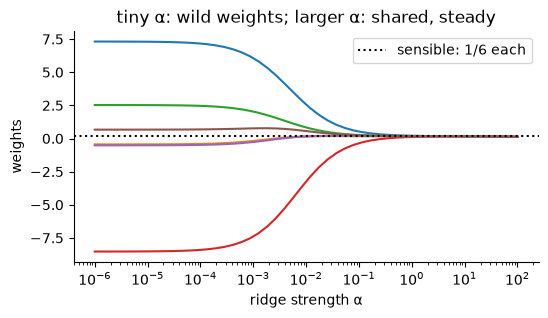

weights at α=1e-6: [ 7.31 -0.44  2.52 -8.53 -0.52  0.67] 
weights at α=1:    [0.206 0.172 0.181 0.121 0.173 0.178]


In [3]:
n, p = 40, 6
base = rng.normal(size=n)
Xc = np.column_stack([base + 0.01 * rng.normal(size=n) for _ in range(p)])   # 6 near-copies of one input
yc = base + 0.3 * rng.normal(size=n)
alphas = np.logspace(-6, 2, 50)
W = np.array([np.linalg.solve(Xc.T @ Xc + a * np.eye(p), Xc.T @ yc) for a in alphas])
plt.figure(figsize=(6, 3)); plt.semilogx(alphas, W); plt.axhline(1 / p, color="k", ls=":", label="sensible: 1/6 each")
plt.xlabel("ridge strength α"); plt.ylabel("weights"); plt.legend(); plt.title("tiny α: wild weights; larger α: shared, steady"); plt.show()
print("weights at α=1e-6:", W[0].round(2), "\nweights at α=1:   ", W[np.argmin(abs(alphas - 1))].round(3))

## 3. Bayesian ridge: the same model with an error bar

The model is written with probabilities:
* **prior** $\mathbf w \sim \mathcal N(0, \alpha^{-1}I)$ (weights are probably small);
* **noise** $y_i \sim \mathcal N(\mathbf w^\top x_i, \beta^{-1})$.

Bayes' theorem gives the posterior of the weights, $\mathcal N(\mathbf m, S)$, with

$$S = (\alpha I + \beta X^\top X)^{-1},\qquad \mathbf m = \beta S X^\top \mathbf y,$$

and the prediction at $x_*$ has mean $\mathbf m^\top x_*$ and variance $\frac1\beta + x_*^\top S x_*$:
* the first term is the noise (**aleatoric**);
* the second is the uncertainty of the weights (**epistemic**), which grows far from the data.

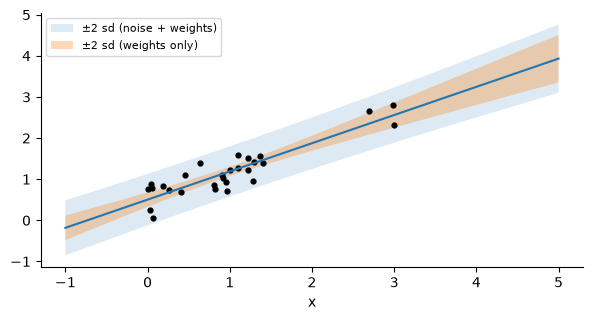

the weight uncertainty is smallest where the data are, and grows outside 0..3


In [4]:
alpha, beta = 1.0, 1 / 0.3 ** 2
S = np.linalg.inv(alpha * np.eye(2) + beta * X.T @ X)
m = beta * S @ X.T @ y
xs = np.linspace(-1, 5, 200); Xs = np.column_stack([xs, np.ones_like(xs)])
mean = Xs @ m
sd_total = np.sqrt(1 / beta + np.einsum("ij,jk,ik->i", Xs, S, Xs))
sd_weights = np.sqrt(np.einsum("ij,jk,ik->i", Xs, S, Xs))
plt.figure(figsize=(7, 3.3))
plt.fill_between(xs, mean - 2 * sd_total, mean + 2 * sd_total, alpha=0.15, label="±2 sd (noise + weights)")
plt.fill_between(xs, mean - 2 * sd_weights, mean + 2 * sd_weights, alpha=0.3, label="±2 sd (weights only)")
plt.plot(xs, mean, "C0"); plt.scatter(x, y, color="k", s=12); plt.legend(fontsize=8); plt.xlabel("x"); plt.show()
print("the weight uncertainty is smallest where the data are, and grows outside 0..3")

Our `models.BayesRidge` uses scikit-learn's `BayesianRidge`, which also *learns* α and β by maximizing the evidence (the marginal likelihood).
**Careful with names:** scikit-learn calls the noise precision `alpha_` and the weight precision `lambda_`, the reverse of the guide's α, β.

In [5]:
from sklearn.linear_model import BayesianRidge
br = BayesianRidge().fit(x[:, None], y)
print(f"learned noise sd = {1 / np.sqrt(br.alpha_):.3f} (truth 0.3);  weight prior sd = {1 / np.sqrt(br.lambda_):.2f}")
print("slope, intercept:", br.coef_.round(3), round(br.intercept_, 3))

learned noise sd = 0.265 (truth 0.3);  weight prior sd = 0.68
slope, intercept: [0.681] 0.509


## 4. Its limit: no curvature

Read noise has a minimum in some settings. A weighted sum of the inputs has no minimum inside the range, but it can if we give it
**nonlinear features** (e.g. $x^2$). Below is the toy world's true $\log\sigma_e$ of one amplifier as VDD is varied, with everything else at nominal.

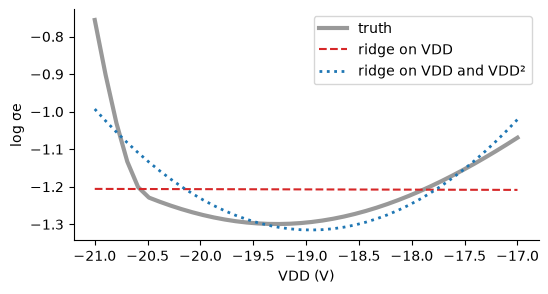

In [6]:
amps = synthetic.make_amplifiers(np.random.default_rng(1234))
i = synthetic.NAMES.index("VDD")
vdd = np.linspace(synthetic.LOW[i], synthetic.HIGH[i], 40)
th = np.tile(synthetic.NOMINAL, (40, 1)); th[:, i] = vdd
true = np.log([synthetic.physics(t, amps[0], 0.0)["sigma_e"] for t in th])
lin = models.BayesRidge().fit(vdd[:, None], true[:, None])
quad = models.BayesRidge().fit(np.column_stack([vdd, vdd ** 2]), true[:, None])
plt.figure(figsize=(6, 3)); plt.plot(vdd, true, "k", lw=3, alpha=0.4, label="truth")
plt.plot(vdd, lin.predict(vdd[:, None])[0], "C3--", label="ridge on VDD")
plt.plot(vdd, quad.predict(np.column_stack([vdd, vdd ** 2]))[0], "C0:", lw=2, label="ridge on VDD and VDD²")
plt.xlabel("VDD (V)"); plt.ylabel("log σe"); plt.legend(); plt.show()

## 5. On the toy CCD: settings + each amplifier's own traces → the three labels

There are no amplifier labels: each row's own trace and reference features carry its identity.

In [7]:
df, curves, Y, groups = toy_scan(120, seed=1)
X, cols = data.make_inputs(df, ("theta", "trace", "ref"), drop_constant=False)
mean, std = grouped_cv(lambda: models.BayesRidge(), X, Y, groups)
_ = report("Bayesian ridge (settings + own traces)", Y, mean, std)

Bayesian ridge (settings + own traces)   sigma_e:  14.2 % (cover 0.72)   lambda:  10.6 % (cover 0.70)   gain:   0.8 % (cover 0.69)


## When to use it

* **Good:** very little data (from ~20 examples); a first baseline; readable weights; never wild.
* **Bad:** optima and interactions, unless you build the nonlinear features yourself.

**Try:** add `"diff"` to the input groups; train on 30 packets instead of 120.

Next: **02 · Decision trees and gradient boosting.**